# Lab: Relationships Between Quantitative Features

Use a historical mammal sleep dataset to compare dreaming, non-dreaming, and total sleep. Use non-dreaming versus total sleep as the main model, then examine whether danger and predation ratings add information. Finally, investigate the nonlinear pattern between gestation time and total sleep.

Support conclusions with the plots and calculations. Explain how well a straight line follows the points and how much variation remains.

## Learning goals

- Describe whether points trend upward or downward, follow a straight or curved pattern, cluster closely around that pattern, or include unusual observations.
- Calculate correlation and interpret R-squared on the correct response scale.
- Recognize nonlinear patterns and compare original gestation with log-transformed gestation.
- Examine additional categorical features visually and compare model R-squared on the same observations.
- Check missing codes, units, category counts, and transformations.
- Distinguish improved fit to observed records from causation and performance on new data.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can answer it?
3. **Evidence:** What should we calculate and display?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete each investigation in order. Use separate cells for individual operations and add cells as needed. Give figures informative titles, named colors, and axis labels with units or transformations. Use the default point transparency and line widths. `ci=None` can omit confidence bands so the patterns and group lines are easier to compare.

## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code and checking every claim against the source and your output. Complete the AI-use reflection at the end.

## Dataset and context

Use the [StatLib mammal sleep data hosted by UC Berkeley](https://www.stat.berkeley.edu/~spector/s100/data/sleep.dat) and its [measurement dictionary](https://www.stat.berkeley.edu/~spector/s100/data/sleep.html). A local copy is supplied as `data/mammal_sleep.csv`.

The supplied `data/mammal_sleep.csv` contains all 62 records and 11 features, including species names and both sleep phases. One row describes a mammal species, not an individual animal or a night. The data trace to Allison and Cicchetti's 1976 study, [Sleep in mammals: ecological and constitutional correlates](https://pubmed.ncbi.nlm.nih.gov/982039/). This is a historical comparative dataset, not a random sample of all mammals; individual collection dates are not supplied.

Course preparation preserves all values and names, gives columns descriptive names, and converts the source's `-999` missing code into blank CSV fields. Use ordinary `pd.read_csv()`; blanks are recognized as missing. The terms dreaming and non-dreaming identify the study's sleep-phase measurements; they are not direct reports of an animal's subjective dream experiences.

### Data dictionary

| Feature | Meaning and units or codes |
| --- | --- |
| `species` | Species label as recorded in the historical source |
| `non_dreaming_sleep` | Non-dreaming sleep in hours per day |
| `dreaming_sleep` | Dreaming sleep in hours per day |
| `body_weight` | Body weight in kilograms |
| `brain_weight` | Brain weight in grams |
| `max_life_span` | Maximum lifespan in years |
| `gestation_time` | Gestation duration in days |
| `predation_index` | Ordered rating, 1–5: lower to higher likelihood of being preyed upon |
| `sleep_exposure_index` | Ordered rating, 1–5: more protected to more exposed sleeping conditions |
| `danger_index` | Ordered rating, 1–5: lower to higher overall danger from other animals |
| `total_sleep` | Total sleep in hours per day; sum of the two phases |

The indices are **ordinal categorical features**, even though stored as numbers. A one-point difference is not a documented equal increment of physical risk. Overall danger incorporates predation, sleep exposure, and other information, so these ratings are not independent measurements. In our models, represent rating levels as categories rather than assuming equal numerical spacing.

## Load and inspect the data

In [1]:
# Import NumPy, Pandas, Matplotlib pyplot, and Seaborn.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [9]:
import pandas as pd
import numpy as np
from pathlib import Path

source = Path.home() / "Downloads" / "sleep.dat"

columns = [
    "species",
    "body_weight",
    "brain_weight",
    "non_dreaming_sleep",
    "dreaming_sleep",
    "total_sleep",
    "max_life_span",
    "gestation_time",
    "predation_index",
    "sleep_exposure_index",
    "danger_index"
]

rows = []

with open(source, "r") as file:
    for line in file:
        parts = line.strip().rsplit(maxsplit=10)
        if len(parts) == 11:
            rows.append(parts)

original_df = pd.DataFrame(rows, columns=columns)

for col in columns[1:]:
    original_df[col] = pd.to_numeric(
        original_df[col], errors="coerce"
)

original_df = original_df.replace(-999.0, np.nan)

mammals_df = original_df[
    [
    "species",
    "non_dreaming_sleep",
    "dreaming_sleep",
    "body_weight",
    "brain_weight",
    "max_life_span",
    "gestation_time",
    "predation_index",
    "sleep_exposure_index",
    "danger_index",
    "total_sleep"
    ]
].copy()

Path("data").mkdir(exist_ok=True)

mammals_df.to_csv(
    "data/mammal_sleep.csv",
    index=False
)

print("Dataset shape:", mammals_df.shape)
display(mammals_df.head())


Dataset shape: (62, 11)


,species,non_dreaming_sleep,dreaming_sleep,body_weight,brain_weight,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index,total_sleep
0,African elephant,NaN,NaN,6654.000,5712.0,38.6,645.0,3,5,3,3.3
1,African giant pouched rat,6.3,2.0,1.000,6.6,4.5,42.0,3,1,3,8.3
2,Arctic Fox,NaN,NaN,3.385,44.5,14.0,60.0,1,1,1,12.5
3,Arctic ground squirrel,NaN,NaN,0.920,5.7,NaN,25.0,5,2,3,16.5
4,Asian elephant,2.1,1.8,2547.000,4603.0,69.0,624.0,3,5,4,3.9


In [10]:
# Display the first five rows.
display(mammals_df.head())

,species,non_dreaming_sleep,dreaming_sleep,body_weight,brain_weight,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index,total_sleep
0,African elephant,NaN,NaN,6654.000,5712.0,38.6,645.0,3,5,3,3.3
1,African giant pouched rat,6.3,2.0,1.000,6.6,4.5,42.0,3,1,3,8.3
2,Arctic Fox,NaN,NaN,3.385,44.5,14.0,60.0,1,1,1,12.5
3,Arctic ground squirrel,NaN,NaN,0.920,5.7,NaN,25.0,5,2,3,16.5
4,Asian elephant,2.1,1.8,2547.000,4603.0,69.0,624.0,3,5,4,3.9


In [11]:
# Display the last five rows.
display(mammals_df.tail())

,species,non_dreaming_sleep,dreaming_sleep,body_weight,brain_weight,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index,total_sleep
57,Tree hyrax,4.9,0.5,2.000,12.3,7.5,200.0,3,1,3,5.4
58,Tree shrew,13.2,2.6,0.104,2.5,2.3,46.0,3,2,2,15.8
59,Vervet,9.7,0.6,4.190,58.0,24.0,210.0,4,3,4,10.3
60,Water opossum,12.8,6.6,3.500,3.9,3.0,14.0,2,1,1,19.4
61,Yellow-bellied marmot,NaN,NaN,4.050,17.0,13.0,38.0,3,1,1,NaN


In [12]:
# Display the shape.
print(mammals_df.shape)

(62, 11)


In [14]:
# Use .info() to inspect the data storage types and non-missing values.
mammals_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   species               62 non-null     object 
 1   non_dreaming_sleep    48 non-null     float64
 2   dreaming_sleep        50 non-null     float64
 3   body_weight           62 non-null     float64
 4   brain_weight          62 non-null     float64
 5   max_life_span         58 non-null     float64
 6   gestation_time        58 non-null     float64
 7   predation_index       62 non-null     int64  
 8   sleep_exposure_index  62 non-null     int64  
 9   danger_index          62 non-null     int64  
 10  total_sleep           58 non-null     float64
dtypes: float64(7), int64(3), object(1)
memory usage: 5.5+ KB


In [15]:
# Count missing values in every feature.
print(mammals_df.isnull().sum())

species                  0
non_dreaming_sleep      14
dreaming_sleep          12
body_weight              0
brain_weight             0
max_life_span            4
gestation_time           4
predation_index          0
sleep_exposure_index     0
danger_index             0
total_sleep              4
dtype: int64


**What does one row represent?**

Your answer:
Each row represents one mammal species and includes information about its sleep patterns, body and brain weight, lifespan, gestation line, and danger ratings. 

**Complete the table using the data dictionary, `.info()`, and `.isnull().sum()`. For data type, use categorical or quantitative. For data storage type, report the Pandas dtype. For missing values, report the count, including 0 when none are missing.**

| Feature | Data type | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `species` | categorical | object | 0 |
| `non_dreaming_sleep` | quantitative | float64 | 14 |
| `dreaming_sleep` | quantitative |float64  | 12 |
| `body_weight` | quantitative | float64 | 0 |
| `brain_weight` | quantitative | float64 | 0 |
| `max_life_span` | quantitative | float64 | 4 |
| `gestation_time` | quantitative | float64 | 4 |
| `predation_index` | categorical | int64 | 0 |
| `sleep_exposure_index` | categorical | int64 | 0 |
| `danger_index` | categorical | int64 | 0 |
| `total_sleep` | quantitative | float64 | 4 |

Your answer:

# Investigation 1: Dreaming, non-dreaming, and total sleep

## Step 1: Question

**How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?**

Compare three relationships in hours per day: dreaming versus non-dreaming, dreaming versus total, and non-dreaming versus total. In the last comparison, use non-dreaming sleep on the horizontal axis and total sleep as the response. This is the main model for Investigation 2.

**Predict the direction and strength of each relationship. Which phase do you expect to be more strongly related to total sleep, and why?**

Your answer:
I predict that dreaming and non dreaming sleep will have a moderate positive relationship because mammals that sleep longer may spend more time in both phases. I expect dreaming sleep and total sleep to have a strong positive relationship, while non dreaming sleep and total sleep will have an even stronger positive relationship. This is because non dreaming sleep generally makes up a larger portion of total sleep.

## Step 2: Data

Create `sleep_df` from records complete for `dreaming_sleep`, `non_dreaming_sleep`, `total_sleep`, `danger_index`, and `predation_index`. Use `.copy()` and keep `mammals_df` unchanged. Use this same subset in all three comparisons and in Investigation 2. How many records were removed from the dataset?

Check that sleep measurements are between 0 and 24 hours per day.

In [17]:
# Prepare sleep_df and check sample size and sleep ranges.

sleep_df = mammals_df.dropna(
    subset=[
        "dreaming_sleep",
        "non_dreaming_sleep",
        "total_sleep",
        "danger_index",
        "predation_index"
    ]
).copy()

print("Original records:", len(mammals_df))
print("Remaining records:", len(sleep_df))
print("Records removed:", len(mammals_df) - len(sleep_df))

display(
    sleep_df[
        ["dreaming_sleep", "non_dreaming_sleep", "total_sleep"]
    ].agg(["min", "max"])
)

sleep_columns = sleep_df[
    ["dreaming_sleep", "non_dreaming_sleep", "total_sleep"]
]

valid_sleep = (
    (sleep_columns >= 0) & (sleep_columns <= 24)
).all().all()

print("All sleep values between 0 and 24:", valid_sleep)

Original records: 62
Remaining records: 48
Records removed: 14


,dreaming_sleep,non_dreaming_sleep,total_sleep
min,0.0,2.1,2.9
max,6.6,17.9,19.9


All sleep values between 0 and 24: True


## Step 3: Evidence

Create three labeled regression plots with `sns.regplot()`: non-dreaming sleep versus dreaming sleep, total sleep versus dreaming sleep, and total sleep versus non-dreaming sleep. In each description, the feature after “versus” goes on the horizontal axis. Calculate the correlation and simple-line R-squared for each pair. Describe the points before relying on the fitted line.

When describing a scatterplot:

- **Direction:** Do the points generally rise or fall from left to right?
- **Form:** Does the overall pattern look roughly straight, curved, or have no clear shape? This describes the arrangement of the points, not the line drawn by the plotting function.
- **Strength:** How closely do the points follow that pattern?
- **Unusual observations:** Which points are far from most of the others?

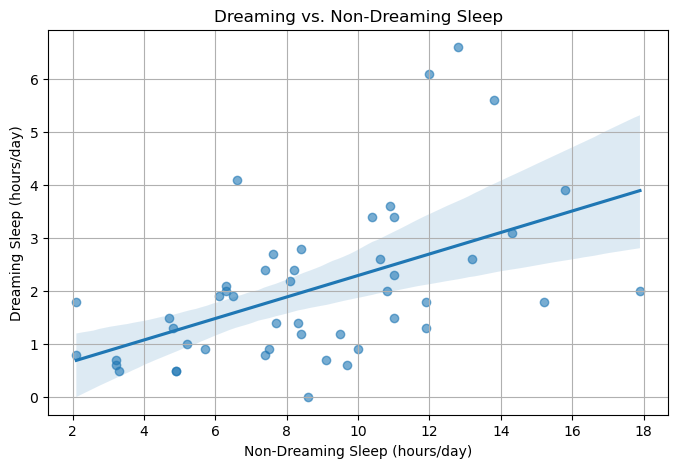

In [18]:
# Plot dreaming sleep and non-dreaming sleep.
plt.figure(figsize=(8, 5))

sns.regplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="dreaming_sleep",
    scatter_kws={"alpha": 0.6}
)

plt.title("Dreaming vs. Non-Dreaming Sleep")
plt.xlabel("Non-Dreaming Sleep (hours/day)")
plt.ylabel("Dreaming Sleep (hours/day)")
plt.grid(True)
plt.show()

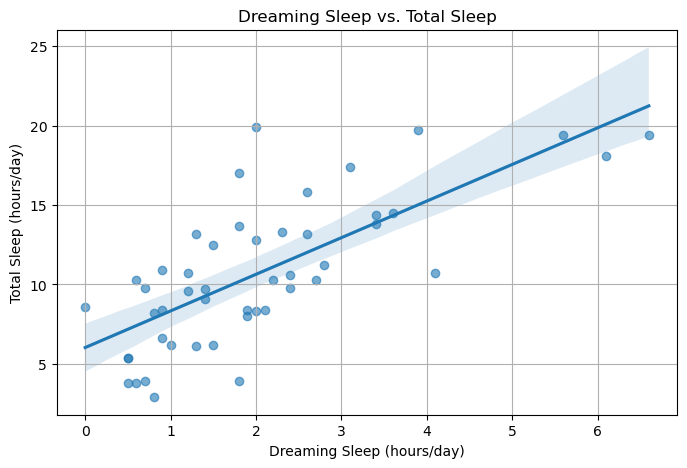

In [19]:
# Plot dreaming sleep and total sleep.
plt.figure(figsize=(8, 5))

sns.regplot(
    data=sleep_df,
    x="dreaming_sleep",
    y="total_sleep",
    scatter_kws={"alpha": 0.6}
)

plt.title("Dreaming Sleep vs. Total Sleep")
plt.xlabel("Dreaming Sleep (hours/day)")
plt.ylabel("Total Sleep (hours/day)")
plt.grid(True)
plt.show()

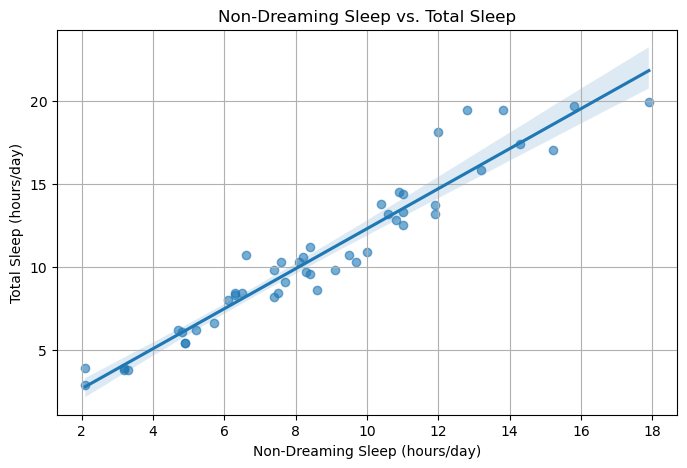

In [20]:
# Plot non-dreaming sleep and total sleep.
plt.figure(figsize=(8, 5))

sns.regplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    scatter_kws={"alpha": 0.6}
)

plt.title("Non-Dreaming Sleep vs. Total Sleep")
plt.xlabel("Non-Dreaming Sleep (hours/day)")
plt.ylabel("Total Sleep (hours/day)")
plt.grid(True)
plt.show()

In [21]:
# Calculate all three correlations and R-squared values.
pairs = [
    ("non_dreaming_sleep", "dreaming_sleep"),
    ("dreaming_sleep", "total_sleep"),
    ("non_dreaming_sleep", "total_sleep")
]

for x, y in pairs:
    r = sleep_df[x].corr(sleep_df[y])
    r_squared = r ** 2

    print(f"{x} vs. {y}")
    print(f"Correlation (r): {r:.4f}")
    print(f"R-squared: {r_squared:.4f}")
    print()

non_dreaming_sleep vs. dreaming_sleep
Correlation (r): 0.5143
R-squared: 0.2645

dreaming_sleep vs. total_sleep
Correlation (r): 0.7271
R-squared: 0.5287

non_dreaming_sleep vs. total_sleep
Correlation (r): 0.9627
R-squared: 0.9268



**For each plot, do the points generally rise or fall? Is their pattern roughly straight or curved, and how closely do they follow it? Identify any unusual observations. Which plot is best summarized by a straight line? Explain what its R-squared tells you about total sleep.**

Your answer:
All three plots show positive relationships, with the points generally rising from left to right. The patterns are roughly linear, although some points are farther from the trend lines. Dreaming versus non-dreaming sleep has the weakest relationship (r = 0.5143, R² = 0.2645). Dreaming versus total sleep has a stronger relationship (r = 0.7271, R² = 0.5287). Non-dreaming versus total sleep has the strongest relationship (r = 0.9627, R² = 0.9268), with points closely following a straight line. A few unusual observations appear farther from the lines, especially in the first two plots. The strongest model explains approximately 92.68% of the variation in total sleep, making non-dreaming sleep the best linear predictor of total sleep among the three comparisons.

## Step 4: Check

Check that `dreaming_sleep + non_dreaming_sleep` agrees with `total_sleep` using `np.isclose()`, which allows for ordinary floating-point rounding. Display several original rows with their phase sum. Then display the three records with the longest non-dreaming sleep and locate their points on the non-dreaming versus total sleep plot. Do the plotted values agree with the records?

In [22]:
# Check the sleep-phase sum and display original measurements.
sleep_df["calculated_total"] = (
    sleep_df["dreaming_sleep"] +
    sleep_df["non_dreaming_sleep"]
)

sleep_df["totals_match"] = np.isclose(
    sleep_df["calculated_total"],
    sleep_df["total_sleep"]
)

print("All totals match:", sleep_df["totals_match"].all())

display(
    sleep_df[
        ["species", "dreaming_sleep",
        "non_dreaming_sleep", "total_sleep",
        "calculated_total", "totals_match"]
    ].head(10)
)

All totals match: True


,species,dreaming_sleep,non_dreaming_sleep,total_sleep,calculated_total,totals_match
1,African giant pouched rat,2.0,6.3,8.3,8.3,True
4,Asian elephant,1.8,2.1,3.9,3.9,True
5,Baboon,0.7,9.1,9.8,9.8,True
6,Big brown bat,3.9,15.8,19.7,19.7,True
7,Brazilian tapir,1.0,5.2,6.2,6.2,True
8,Cat,3.6,10.9,14.5,14.5,True
9,Chimpanzee,1.4,8.3,9.7,9.7,True
10,Chinchilla,1.5,11.0,12.5,12.5,True
11,Cow,0.7,3.2,3.9,3.9,True
12,Desert hedgehog,2.7,7.6,10.3,10.3,True


In [23]:
# Inspect the three records with the longest non-dreaming sleep.

longest_sleep = sleep_df.nlargest(
    3, 'non_dreaming_sleep'
)

display(
    longest_sleep[
        ['species', 'non_dreaming_sleep',
         'dreaming_sleep', 'total_sleep']
        ]
)

,species,non_dreaming_sleep,dreaming_sleep,total_sleep
32,Little brown bat,17.9,2.0,19.9
6,Big brown bat,15.8,3.9,19.7
41,Owl monkey,15.2,1.8,17.0


## Step 5: Conclusion

**Research question:** How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?


**Do mammals that spend more time in dreaming sleep also tend to spend more time in non-dreaming sleep? Which phase is more strongly related to total sleep? Support your answers with the plots, correlations, and R-squared values. Did the results match your prediction?**

Your answer:
Mammals that spend more time in dreaming sleep generally also spend more time in non-dreaming sleep. Their relationship is moderately positive (r = 0.5143, R² = 0.2645). Dreaming sleep and total sleep have a stronger relationship (r = 0.7271, R² = 0.5287). However, non-dreaming sleep has the strongest relationship with total sleep (r = 0.9627, R² = 0.9268), explaining approximately 92.68% of its variation in a linear model. The results support my prediction that non-dreaming sleep would have the stronger relationship with total sleep. However, total sleep includes both phases, so this strong relationship is partly mathematical.

## Step 6: Limitation

**State two limitations specific to these sleep relationships. Explain why a stronger correlation is not automatically a better scientific explanation.**

Your answer:
One limitation is that 14 of the 62 mammal records were excluded because of missing sleep measurements, which could affect how representative the results are. A second limitation is that total sleep is calculated by adding dreaming and non-dreaming sleep, so the variables are not independent. This means a stronger correlation does not automatically provide a better scientific explanation or prove that one sleep phase causes longer total sleep.

# Investigation 2: Do danger and predation add information?

## Step 1: Question

**Do danger and predation categories add information about total sleep beyond non-dreaming sleep?**

**Predict whether each index will add substantial, small, or little visible information. What would you look for at comparable non-dreaming-sleep durations?**

Your answer:
I predict that the danger index will add a small amount of information and the predation index will add little additional information beyond non-dreaming sleep. I would look for differences in total sleep among mammals with similar non-dreaming sleep durations. If the groups show clear separation instead of overlapping, that would suggest the indices provide additional information.



## Step 2: Data

Reuse `sleep_df` and its original sleep measurements. Count records for each danger and predation rating and display a cross-tabulation of the two indices. Keep all five original levels in their natural order. Higher predation index values mean a mammal is more likely to be preyed upon. Higher danger index values mean greater overall danger from other animals.

In [24]:
# Count the records at each danger and predation level.

print("Danger index counts:")
print(sleep_df["danger_index"].value_counts().reindex(range(1, 6), fill_value=0).sort_index())

print("\nPredation index counts:")
print(sleep_df["predation_index"].value_counts().reindex(range(1, 6), fill_value=0).sort_index())

Danger index counts:
danger_index
1    14
2    12
3     8
4     9
5     5
Name: count, dtype: int64

Predation index counts:
predation_index
1    10
2    13
3     9
4     7
5     9
Name: count, dtype: int64


In [25]:
# Cross-tabulate danger and predation ratings.

cross_tab = pd.crosstab(
    sleep_df["danger_index"],
    sleep_df["predation_index"]
)

cross_tab = cross_tab.reindex(
    index=range(1, 6),
    columns=range(1, 6),
    fill_value=0
)

display(cross_tab)

predation_index,1,2,3,4,5
danger_index,,,,,
1,10,4,0,0,0
2,0,9,3,0,0
3,0,0,5,2,1
4,0,0,1,5,3
5,0,0,0,0,5


## Step 3: Evidence

Use `sns.lmplot()` twice on the non-dreaming–total sleep relationship, once colored by `danger_index` and once by `predation_index`. Set `hue_order=[1, 2, 3, 4, 5]`, use a named palette, and label the legend so the index direction is clear. The separate lines show group patterns; small groups may produce unstable lines. Compare groups where their non-dreaming-sleep ranges overlap.

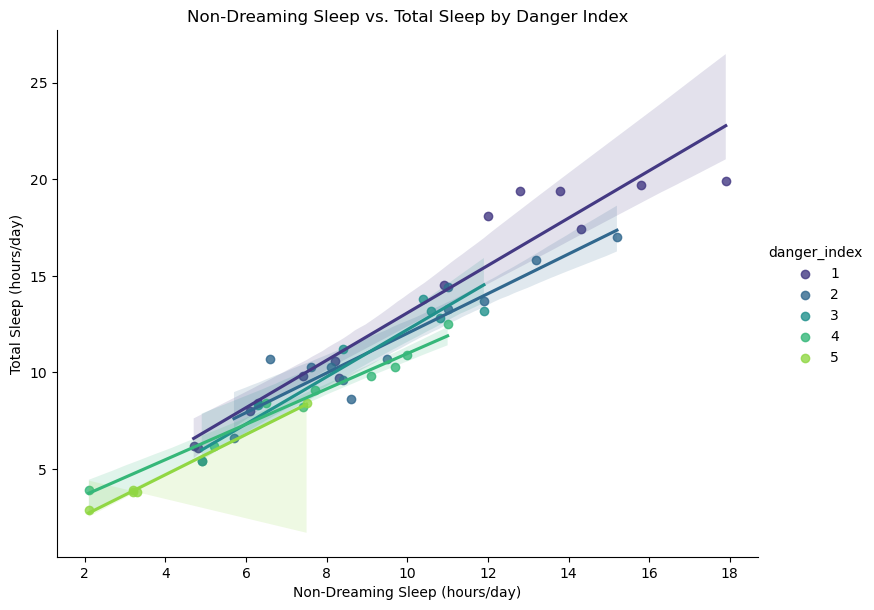

In [26]:
# Plot the non-dreaming–total sleep relationship by danger category.

sns.lmplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    hue="danger_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    height=6,
    aspect=1.3
)

plt.title("Non-Dreaming Sleep vs. Total Sleep by Danger Index")
plt.xlabel("Non-Dreaming Sleep (hours/day)")
plt.ylabel("Total Sleep (hours/day)")
plt.show()

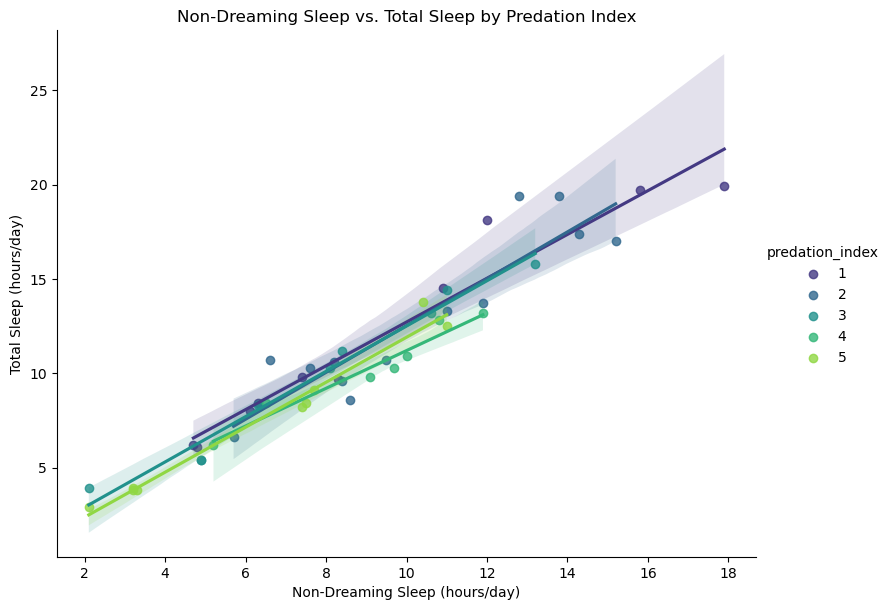

In [27]:
# Plot the non-dreaming–total sleep relationship by predation category.

sns.lmplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    hue="predation_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    height=6,
    aspect=1.3
)

plt.title("Non-Dreaming Sleep vs. Total Sleep by Predation Index")
plt.xlabel("Non-Dreaming Sleep (hours/day)")
plt.ylabel("Total Sleep (hours/day)")
plt.show()

**Describe overlap and separation in each plot. How do the group sizes and available non-dreaming-sleep ranges affect your interpretation?**

Your answer:
Both plots show a strong positive relationship between non-dreaming sleep and total sleep. The danger index groups overlap, although lower danger ratings generally appear to have slightly higher total sleep at similar non-dreaming sleep durations. The predation index groups also overlap considerably, with only small differences between their regression lines. Some groups have fewer observations, such as danger level 5 with only 5 mammals, making their regression lines less reliable. The groups also cover different ranges of non-dreaming sleep, making direct comparisons difficult. Overall, the indices may provide some additional information, but the separation is limited.


### Compare model R-squared

The supplied helper follows the lecture's least-squares calculation. Read and run it; you do not need to recreate its matrix operations. `pd.get_dummies()` represents each rating with category indicators. `drop_first=True` chooses a reference level. This avoids assuming equal distances between index values.

These are **additive models**: one shared slope for the quantitative predictor and category-specific intercept adjustments. They differ from the separate group slopes in `lmplot()`. Compare the baseline, baseline plus danger, baseline plus predation, and baseline plus both, all on identical rows and the same response scale. Training R-squared cannot decrease when predictors are added to these nested models; an increase alone does not establish improved performance on new observations.

In [28]:
def calculate_r_squared(data, predictor, response, categorical_features):
    predictors = pd.get_dummies(
        data[[predictor, *categorical_features]],
        columns=categorical_features, drop_first=True, dtype=float
    )
    predictors.insert(0, "intercept", 1.0)
    x = predictors.to_numpy(dtype=float)
    y = data[response].to_numpy(dtype=float)
    fitted = x @ np.linalg.lstsq(x, y, rcond=None)[0]
    return 1 - ((y - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum()

In [33]:
# Build and display phase_comparison for the four models.

models = {
    "Baseline": [],
    "Baseline + Danger": ["danger_index"],
    "Baseline + Predation": ["predation_index"],
    "Baseline + Both": ["danger_index", "predation_index"]
}

results = []

for name, features in models.items():
    r2 = calculate_r_squared(
        sleep_df,
        "non_dreaming_sleep",
        "total_sleep",
        features
)

    results.append({
    "Model": name,
    "R-squared": r2
})

phase_comparison = pd.DataFrame(results)
display(phase_comparison)

,Model,R-squared
0,Baseline,0.926820
1,Baseline + Danger,0.942657
2,Baseline + Predation,0.937084
3,Baseline + Both,0.951454


## Step 4: Check

For each danger rating, display the smallest and largest non-dreaming sleep values using `.groupby()` and `.agg(["min", "max"])`. Repeat for predation ratings.

Compare these ranges with the group plots. Use the ranges to identify where two groups actually have observations at similar non-dreaming sleep durations.

# Display the non-dreaming sleep range for each danger and predation rating.

print("Danger Index:")
display(
    sleep_df.groupby("danger_index")["non_dreaming_sleep"]
    .agg(["min", "max"])
)

print("Predation Index:")
display(
    sleep_df.groupby("predation_index")["non_dreaming_sleep"]
    .agg(["min", "max"])
)

**Choose two danger groups. Over what range of non-dreaming sleep do both groups have observations? Why should you compare their lines within that shared range?**

Your answer:
I chose danger index groups 1 and 2. Group 1 has non-dreaming sleep values from 4.7 to 17.9 hours, while group 2 ranges from 5.7 to 15.2 hours. Their shared range is 5.7 to 15.2 hours per day. Comparing their regression lines within this range is important because both groups have observations there. Comparing outside this range could lead to unreliable conclusions because the lines would be predicting beyond the observed data.

## Step 5: Conclusion

**Research question:** Do danger and predation categories add information about total sleep beyond non-dreaming sleep?

**Does adding danger, predation, or both improve the model of total sleep? Report the four R-squared values and how much each changes from non-dreaming sleep alone. Are the improvements small or large? Explain how the group plots support your answer.**

Your answer:
The baseline model has an R-squared of 0.926820. Adding danger increases it to 0.942657, an improvement of 0.015837. Adding predation increases it to 0.937084, an improvement of 0.010264. Adding both increases it to 0.951454, an improvement of 0.024634. These are relatively small improvements because non-dreaming sleep already explains most of the variation in total sleep. The group plots show some separation between categories, but the regression lines overlap considerably. Overall, danger and predation add a small amount of information, with the combined model having the highest R-squared. However, these results do not establish better predictions on new data.

## Step 6: Limitation

**Identify two limitations of this investigation.**

One limitation is the small number of mammals in certain danger and predation categories, which can make the regression lines less reliable. A second limitation is that the categories have different ranges of non-dreaming sleep, making comparisons difficult when groups do not overlap. Also, higher R-squared values do not necessarily mean the models will predict new observations better.


# Investigation 3: Gestation time and total sleep

## Step 1: Question

**How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?**

Gestation time is the length of a pregnancy, measured in days. We will compare it with total sleep, measured in hours per day, and see whether taking the logarithm of gestation time makes the pattern look straighter.

**Do you expect mammals with longer pregnancies to sleep more hours per day, fewer hours, or about the same amount? Explain your initial guess. You do not need prior knowledge about mammals; you will compare your prediction with the data.**

Your answer:
I predict that mammals with longer gestation times will tend to sleep fewer hours per day. I think there may be a negative relationship between gestation time and total sleep, although other factors could influence the results.

## Step 2: Data

Create `gestation_df` by dropping rows missing `gestation_time`, `total_sleep`, `danger_index`, or `predation_index`, then copying the result. How many records were removed from the dataset? Do not drop rows merely because maximum lifespan is missing. Check that gestation is positive and sleep is between 0 and 24 hours per day. Create `log10_gestation_time` only after checking the inputs.

In [35]:
# Prepare gestation_df and check counts and plausible ranges.

import numpy as np

gestation_df = mammals_df.dropna(
    subset=["gestation_time", "total_sleep", "danger_index", "predation_index"]
).copy()

print("Original records:", len(mammals_df))
print("Remaining records:", len(gestation_df))
print("Records removed:", len(mammals_df) - len(gestation_df))

print("Gestation range:", gestation_df["gestation_time"].min(),
    "to", gestation_df["gestation_time"].max())

print("Sleep range:", gestation_df["total_sleep"].min(),
"to", gestation_df["total_sleep"].max())

assert (gestation_df["gestation_time"] > 0).all()
assert gestation_df["total_sleep"].between(0, 24).all()

gestation_df["log10_gestation_time"] = np.log10(
    gestation_df["gestation_time"]
)

display(gestation_df.head())

Original records: 62
Remaining records: 54
Records removed: 8
Gestation range: 12.0 to 645.0
Sleep range: 2.6 to 19.9


,species,non_dreaming_sleep,dreaming_sleep,body_weight,brain_weight,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index,total_sleep,log10_gestation_time
0,African elephant,NaN,NaN,6654.000,5712.0,38.6,645.0,3,5,3,3.3,2.809560
1,African giant pouched rat,6.3,2.0,1.000,6.6,4.5,42.0,3,1,3,8.3,1.623249
2,Arctic Fox,NaN,NaN,3.385,44.5,14.0,60.0,1,1,1,12.5,1.778151
3,Arctic ground squirrel,NaN,NaN,0.920,5.7,NaN,25.0,5,2,3,16.5,1.397940
4,Asian elephant,2.1,1.8,2547.000,4603.0,69.0,624.0,3,5,4,3.9,2.795185


## Step 3: Evidence

Plot sleep against gestation on original scales, then against log10 gestation, leaving sleep in hours per day. Calculate correlation and simple-line R-squared for each. These R-squared values share the same response scale and observations. Compare whether the points follow a straight or curved pattern and how widely they are scattered, as well as the numerical summaries.

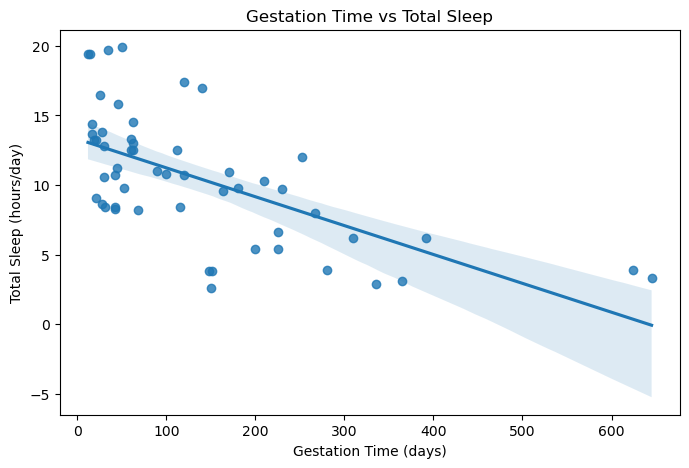

In [37]:
# Plot original gestation and sleep.

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.regplot(
    data=gestation_df,
    x="gestation_time",
    y="total_sleep"
)
plt.title("Gestation Time vs Total Sleep")
plt.xlabel("Gestation Time (days)")
plt.ylabel("Total Sleep (hours/day)")
plt.show()

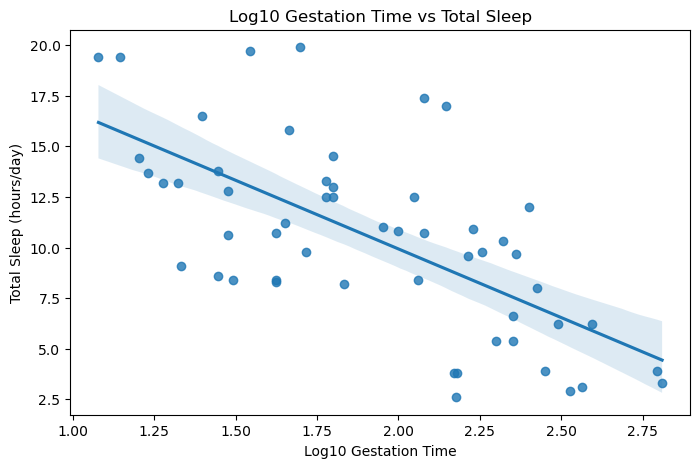

In [38]:
# Plot log gestation and sleep.

plt.figure(figsize=(8, 5))
sns.regplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep"
)
plt.title("Log10 Gestation Time vs Total Sleep")
plt.xlabel("Log10 Gestation Time")
plt.ylabel("Total Sleep (hours/day)")
plt.show()

In [39]:
# Calculate the two correlations and squared correlations.

r_original = gestation_df["gestation_time"].corr(
    gestation_df["total_sleep"]
)

r_log = gestation_df["log10_gestation_time"].corr(
    gestation_df["total_sleep"]
)

print("Original correlation:", round(r_original, 4))
print("Original R-squared:", round(r_original**2, 4))

print("Log correlation:", round(r_log, 4))
print("Log R-squared:", round(r_log**2, 4))

Original correlation: -0.6313
Original R-squared: 0.3986
Log correlation: -0.6637
Log R-squared: 0.4404


**What changes when gestation is log-transformed? Does the transformation remove the scatter or only improve the straight-line summary modestly?**

Your answer:
Log transforming gestation time makes the negative relationship with total sleep appear slightly more linear. The original correlation was -0.6313 with R squared of 0.3986 while the log transformed correlation was -0.6637 with an R squared of 0.4404. This means the log transformation improves the straight line fit modesty, explaining about 44% of the variation in total sleep compared to about 40% originally. However, the points are still widely scattered so the transformation does not eliminate the variability.

Reuse the group-plot and model-comparison approach from Investigation 2, now using `log10_gestation_time` as the predictor and `total_sleep` as the response. Count observations at each rating level in this subset before interpreting the group lines. Examine danger and predation separately, then compare all four additive models on `gestation_df`.

In [40]:
# Count ratings in the sleep subset.

print("Danger index counts:")
print(gestation_df["danger_index"].value_counts().sort_index())

print("\nPredation index counts:")
print(gestation_df["predation_index"].value_counts().sort_index())

Danger index counts:
danger_index
1    16
2    12
3    10
4     9
5     7
Name: count, dtype: int64

Predation index counts:
predation_index
1    12
2    14
3     9
4     7
5    12
Name: count, dtype: int64


<Figure size 900x600 with 0 Axes>

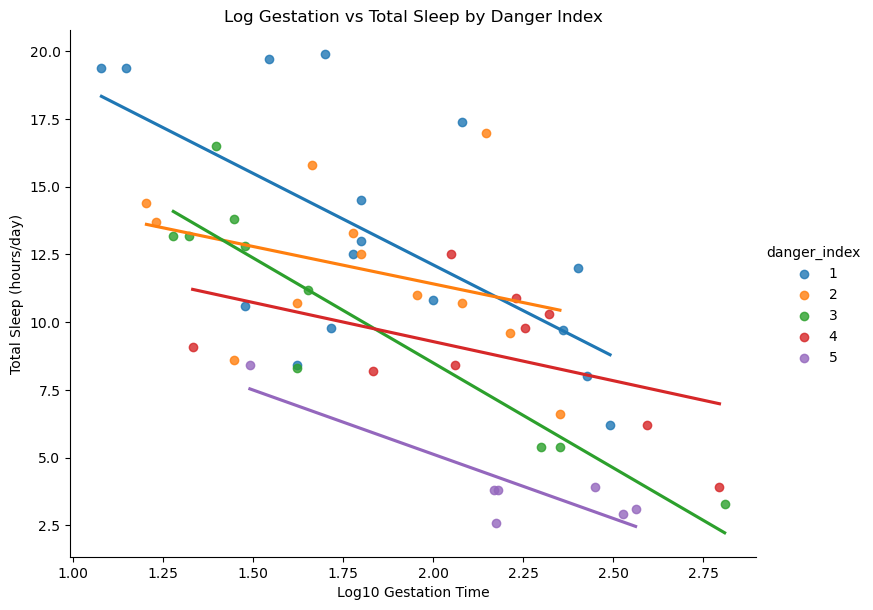

In [41]:
# Plot log gestation and sleep by danger.

plt.figure(figsize=(9, 6))

sns.lmplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep",
    hue="danger_index",
    height=6,
    aspect=1.3,
    ci=None
)

plt.title("Log Gestation vs Total Sleep by Danger Index")
plt.xlabel("Log10 Gestation Time")
plt.ylabel("Total Sleep (hours/day)")
plt.show()

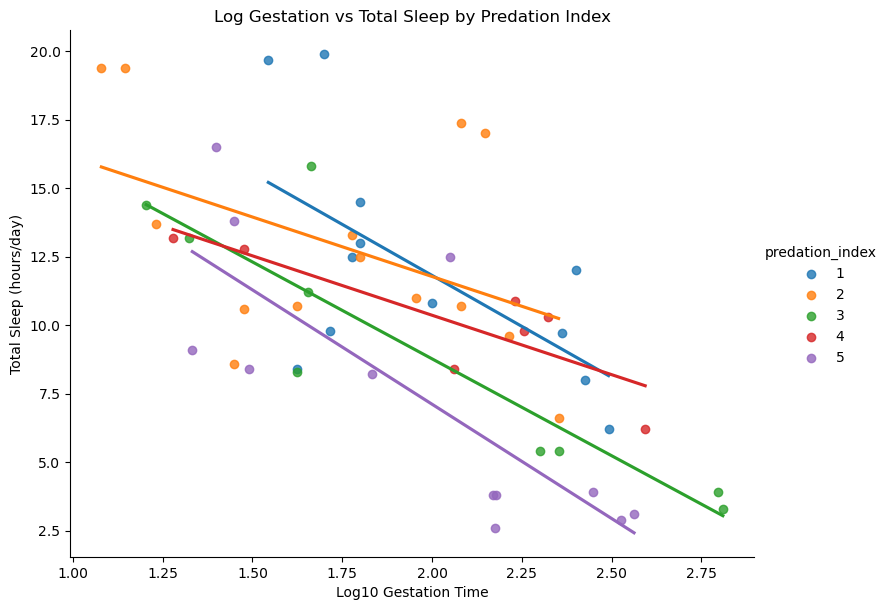

In [42]:
# Plot log gestation and sleep by predation.

sns.lmplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep",
    hue="predation_index",
    height=6,
    aspect=1.3,
    ci=None
)

plt.title("Log Gestation vs Total Sleep by Predation Index")
plt.xlabel("Log10 Gestation Time")
plt.ylabel("Total Sleep (hours/day)")
plt.show()

In [43]:
# Build and display sleep_comparison for the four models.

import pandas as pd
import statsmodels.formula.api as smf

models = {
    "Log gestation only":
        "total_sleep ~ log10_gestation_time",
    "Log gestation + danger":
        "total_sleep ~ log10_gestation_time + C(danger_index)",
    "Log gestation + predation":
        "total_sleep ~ log10_gestation_time + C(predation_index)",
    "Log gestation + both":
        "total_sleep ~ log10_gestation_time + C(danger_index) + C(predation_index)"
}

results = []

for name, formula in models.items():
    model = smf.ols(formula, data=gestation_df).fit()
    results.append({
        "Model": name,
        "R-squared": round(model.rsquared, 4),
        "Adjusted R-squared": round(model.rsquared_adj, 4)
})

sleep_comparison = pd.DataFrame(results)
display(sleep_comparison)

,Model,R-squared,Adjusted R-squared
0,Log gestation only,0.4404,0.4297
1,Log gestation + danger,0.6542,0.6181
2,Log gestation + predation,0.5917,0.5491
3,Log gestation + both,0.6943,0.6317


## Step 4: Check

For the first five records, display gestation time, its logarithm, and `10 ** log10_gestation_time`. Does reversing the logarithm recover the original number of days?

Display the records with the shortest and longest gestation times. Find their points in both plots and compare the recorded sleep hours with their vertical positions. The horizontal positions change when gestation is transformed; the sleep measurements stay the same.

In [44]:
# Reverse the logarithm for five records and compare with the original gestation times.

check_df = gestation_df[
    ["gestation_time", "log10_gestation_time"]
].head(5).copy()

check_df["recovered_gestation"] = (
    10 ** check_df["log10_gestation_time"]
)

display(check_df)

print("All values recovered:",
    np.allclose(
        check_df["gestation_time"],
        check_df["recovered_gestation"]
))

,gestation_time,log10_gestation_time,recovered_gestation
0,645.0,2.809560,645.0
1,42.0,1.623249,42.0
2,60.0,1.778151,60.0
3,25.0,1.397940,25.0
4,624.0,2.795185,624.0


All values recovered: True


In [45]:
# Inspect extreme gestation records.

shortest = gestation_df.nsmallest(1, "gestation_time")
longest = gestation_df.nlargest(1, "gestation_time")

extremes = pd.concat([shortest, longest])

display(extremes[
    ["species", "gestation_time",
    "log10_gestation_time", "total_sleep"]
])

,species,gestation_time,log10_gestation_time,total_sleep
38,N. American opossum,12.0,1.079181,19.4
0,African elephant,645.0,2.809560,3.3


**Did reversing the logarithm recover the original gestation times? For the shortest and longest gestation records, do both plots show the recorded total sleep values? Describe what changed between the plots and what stayed the same.**

Your answer:
Yes, reversing the logarithm recovered the original gestation times for all five records. The North American opossum had the shortest gestation time at 12 days and slept 19.4 hours per day. The African elephant had the longest gestation time at 645 days and slept 3.3 hours per day. Both plots show these same sleep values. Only the horizontal positions changed because gestation time was log-transformed. The vertical positions stayed the same because total sleep was not transformed.

## Step 5: Conclusion

**Research question:** How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?

**Do mammals with longer gestation times tend to sleep more or less? Does using log gestation make the pattern look straighter? Do danger and predation add information? Support your answers with the plots, correlation, and R-squared values, and compare the results with your prediction.**

Your answer:
The results support my prediction that mammals with longer gestation times tend to sleep fewer hours per day. The original correlation was -0.6313, while the log-transformed correlation was -0.6637, showing a moderately strong negative relationship. Log-transforming gestation made the pattern slightly more linear and increased R-squared from 0.3986 to 0.4404.

Adding danger and predation improved the models. The R-squared increased to 0.6542 with danger and 0.5917 with predation. Including both produced the highest R-squared of 0.6943 and adjusted R-squared of 0.6317. This suggests that danger and predation provide additional information about sleep beyond gestation time. However, the data still show variability, and these relationships do not prove causation.

## Step 6: Limitation

**Identify two limitations of the gestation and sleep investigation.**

Your answer:
One limitation is that the dataset contains only 54 complete records for this investigation, so it may not represent all mammal species. A second limitation is that other factors, such as body size, habitat, and environmental conditions, may influence sleep but were not included in these models.

## AI-use reflection

**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:
I used ChatGPT to help write and organize Python code and interpret the results. I checked the suggested code by running it in JupyterLab and comparing the explanations with my graphs, correlation values, and R-squared outputs. I accepted the suggestions that matched my actual results.

## Submission checklist

- Use the supplied CSV with a relative path.
- Complete the dictionary table and every written response.
- Include a prediction and all six workflow steps for each investigation.
- Include all three sleep comparison plots, two non-dreaming–total group plots, original and log-gestation sleep plots, and two sleep group plots.
- Keep observations consistent within each comparison; report counts and investigate exclusions.
- Interpret correlation and R-squared on the correct scale, using numerical and visual evidence.
- Compare baseline, danger, predation, and combined models without claiming automatic causal or predictive improvement.
- Explain whether the patterns are straight or curved, how the log transformation changes the gestation plot, and what the analyses cannot tell us.
- Complete the AI-use reflection, restart the kernel, and run the notebook in order before submitting.